In [1]:
from main import *

/home/matthew/Documents/research/miller/kaczmarz-batch-selection/main.py:170: RuntimeWarning: invalid value encountered in log
  return r * np.log((np.sqrt(e0) - r) / (np.sqrt(error) - r))


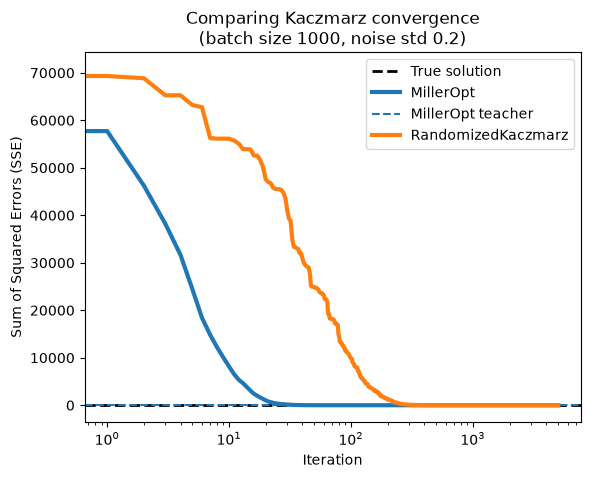

In [2]:
# Generate system
rng = np.random.default_rng(seed=1)
n, d = (1000, 50)
n_noised = n // 10
A, x, b = get_system(rng, n, d)

b_noise_scale = 0.2
noised_indices = rng.choice(n, size=n_noised, replace=False)
b_noised = b
b_noised[noised_indices] += rng.normal(scale=b_noise_scale, size=n_noised)

x_teacher = x + 1e-1 * rng.normal(size=d)

x0 = rng.normal(scale=50, size=d)

iters = 5000

common_params = dict(
    x0=x0,
    A=A,
    b=b_noised,
    x_sol=x,
    batch_size=n,
    maxiter=iters
)

sols = [
    MillerOpt(**common_params, teacher=x_teacher, noised_indices=noised_indices),
    RandomizedKaczmarz(**common_params),
]

for sol in sols:
    sol.solve()

comparison = Comparison(sols)
comparison.plot_residuals(
    title=f"Comparing Kaczmarz convergence\n(batch size {common_params["batch_size"]}, noise std {b_noise_scale})",
    logx=True,
    logy=False
)

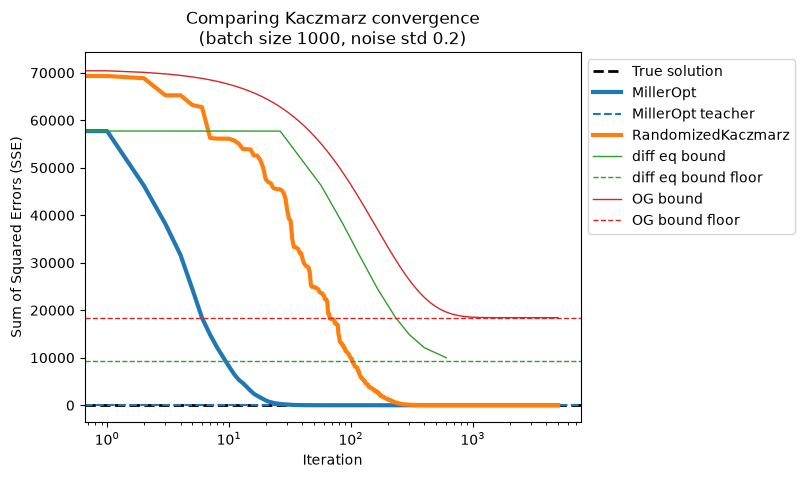

In [3]:
time_bounds = np.array(sols[0].diagnostics["time bounds"])

comparison.plot_residuals(
    title=f"Comparing Kaczmarz convergence\n(batch size {common_params["batch_size"]}, noise std {b_noise_scale})",
    logx=True,
    logy=False
)

plt.plot(time_bounds[:, 0], time_bounds[:, 1], color="tab:green", label="diff eq bound", lw=1)
plt.axhline(sols[0].diagnostics["tb_floor"], label=f"diff eq bound floor", ls="--", color="tab:green", lw=1)

# plt.plot(sols[0].diagnostics["bounds"], color="tab:red", label="OG bound")
iter_range = np.arange(iters)
e0 = sols[0].scores[0]
og_floor = sols[0].diagnostics["b_floor"]
plt.plot(iter_range, (1 - sols[0].alpha / 2)**iter_range * (e0 - og_floor) + og_floor, color="tab:red", label="OG bound", lw=1)
plt.axhline(og_floor, color="tab:red", ls="--", label="OG bound floor", lw=1)

plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

In [8]:
print(f"alpha: {sols[0].alpha}")
print(f"beta:  {sols[0].beta}")
print(f"gamma: {sols[0].gamma}")

alpha: 0.012495345983451986
beta:  1.1980561218332744
gamma: 0.36012237769080185
